![Banner](../images/09_09_banner_rs_image_classification.png)


# Change Detection: Classical, Post-Classification and Deep Methods on Landsat and Sentinel-2, 2020 to 2025

Change detection asks *what is different between two dates*.


## Overview

It sounds simple, but a difference between two images can come from many sources besides a change on the ground: misregistration, atmosphere and sun angle, sensor differences, and the timing of the season. In the US Corn Belt it has an extra twist: **most fields change crop every year** (the corn-soybean rotation), so "change" is the rule, not the exception.

This notebook compares the main families of change detection on the same AOI (`Corn_belt/aoi.geojson`, north-central Iowa), all with `geolattice.rsense.classify` (`classify`) and `geolattice.rsense.classify.image_classification` (`ic`):

1. **Before you compare:** `check_coregistration` and radiometric normalisation (`histogram_match`).
2. **Classical methods:** `image_difference`, `image_ratio`, `change_vector_analysis` / `classify.cva`, `pca_change`, with ±kσ and Otsu thresholds (`image_processing.threshold`, chapter 01).
3. **Post-classification change:** `classify.post_classification` on two classified years, and the from-to matrix, with the corn ↔ soybean rotation as a known "change".
4. **The CDL as reference:** year-to-year CDL differences, their own error, and what counts as true change.
5. **Deep change detection:** `build_change_model` (Siamese-difference, Siamese-concatenation and early-fusion U-Nets, a BIT-style transformer) trained with `PairChipDataset`.
6. **Evaluation:** `change_metrics` (precision, recall, F1 and IoU of the change class) and an area-adjusted change area with `olofsson`.

**Exercise:** a rotation map 2024 → 2025 from Landsat vs from the CDL, and where and why they disagree.

The classical and post-classification sections run on a CPU in a few minutes; the deep section needs a GPU (about 6 minutes on one RTX A5500; on a CPU reduce `EPOCHS`).


## Core concepts

### Learning objectives

1. Check that two dates are co-registered and radiometrically comparable before computing any difference, and recognise when normalisation helps and when it removes real change.
2. Explain the mathematics of image differencing, ratioing, change vector analysis and PCA change detection, and choose a threshold (±kσ vs Otsu) that suits the share of change.
3. Build a from-to matrix by post-classification comparison and read it, including the error that two independent maps add.
4. Judge a change reference: how often the CDL changes, how much of that is rotation, how much is label noise at field edges.
5. Explain and train Siamese and early-fusion change networks and a bitemporal transformer, and apply them across sensors.
6. Evaluate change maps with change-class precision, recall, F1 and IoU, and estimate the change **area** with confidence intervals from a stratified sample (Olofsson et al., 2014).

### Contents

1. Setup: libraries, device and data paths
2. The data: mid-July Landsat and Sentinel-2 pairs and CDL on one 30 m grid
3. Before you compare: co-registration and radiometric normalisation
4. Classical methods: difference, ratio, change vector analysis, PCA and thresholds
5. Post-classification change: the from-to matrix
6. The CDL as reference: what counts as true change?
7. Deep change detection: Siamese, early-fusion and transformer networks
8. Evaluation: change metrics and area-adjusted change area
9. Exercise: the rotation map from Landsat vs from the CDL
10. Summary of the experiments
11. Interpretation, caveats and recommended recipe


### Task and evaluation design

**Data:** Landsat 8 surface reflectance of 12 July 2024 and 15 July 2025 (the test pair), 20 July 2021 and 10 July 2023 (training years for the *Post-classification change: the from-to matrix* section); Sentinel-2 L2A of mid-July 2020 to 2025 averaged to 30 m; CDL 2020 to 2025 at 30 m. All on the 30 m Landsat grid (UTM 15N, 1011 × 971 px), six harmonised bands (blue, green, red, NIR, SWIR-1, SWIR-2; Sentinel-2 B8A for NIR).

**Task.** Binary change between **2024 and 2025**: a pixel *changed* when its CDL class (six classes: corn, soybeans, grass/pasture, developed, wetland/forest, other) differs between the two years. The two images are an *anniversary pair* (same week of the year), which removes most of the seasonal difference, but not all of it.

**Splits.** Nothing from 2024 or 2025 is used for training: the post-classification Random Forest is trained on 2021 and 2023, the deep models on the Sentinel-2 pairs 2020→2021, 2021→2022 and 2022→2023, with 2023→2024 for model selection.

**Caveat.** The CDL is a classification product with its own errors; the *The CDL as reference: what counts as true change?* section examines how much of its "change" is real.


## Setup: libraries, device and data paths

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings  # JSON, timing and warning control
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours
from scipy import ndimage as ndi  # image morphology and filters
import torch  # PyTorch: the deep change models
import geolattice.rsense.classify as classify  # GeoLattice classification helpers (cva, post_classification)
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module
import geolattice.rsense.image_processing as ip  # GeoLattice image-processing functions

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # the data folder, from the notebook folder or the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
# Landsat, Sentinel-2 and CDL folders
L_DIR, S2_DIR, CDL_DIR = DATA / "Landsat_9", DATA / "Sentinel_2", DATA / "CDL" / "30_m"
OUT = DATA / "outputs" / "change_detection"  # output folder
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("torch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only: the classical sections run fine; reduce EPOCHS for Section 5")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
rng = np.random.default_rng(SEED)  # random generator
EPOCHS = 40 if DEVICE == "cuda" else 6  # training epochs (fewer on a CPU)


torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## The data: mid-July Landsat and Sentinel-2 pairs and CDL on one 30 m grid

Landsat Collection 2 Level-2 reflectance is $\rho = 2.75\cdot10^{-5}\,DN-0.2$; the `QA_PIXEL` band flags fill, dilated cloud, cirrus, cloud and cloud shadow (bits 0 to 4), which are masked. Sentinel-2 bands are averaged onto the Landsat grid and masked with the scene classification layer. The CDL is reprojected by nearest neighbour (labels must never be interpolated) and recoded to six classes.


loaded in 5 s | grid 1011 x 971 px at 30 m, EPSG:32615
masked (cloud/shadow/fill) share: {'Landsat 2021': '0.00%', 'Landsat 2023': '0.07%', 'Landsat 2024': '6.78%', 'Landsat 2025': '2.14%'} {'S2 2020': '0.54%', 'S2 2021': '0.09%', 'S2 2022': '0.00%', 'S2 2023': '0.00%', 'S2 2024': '4.38%', 'S2 2025': '0.00%'}


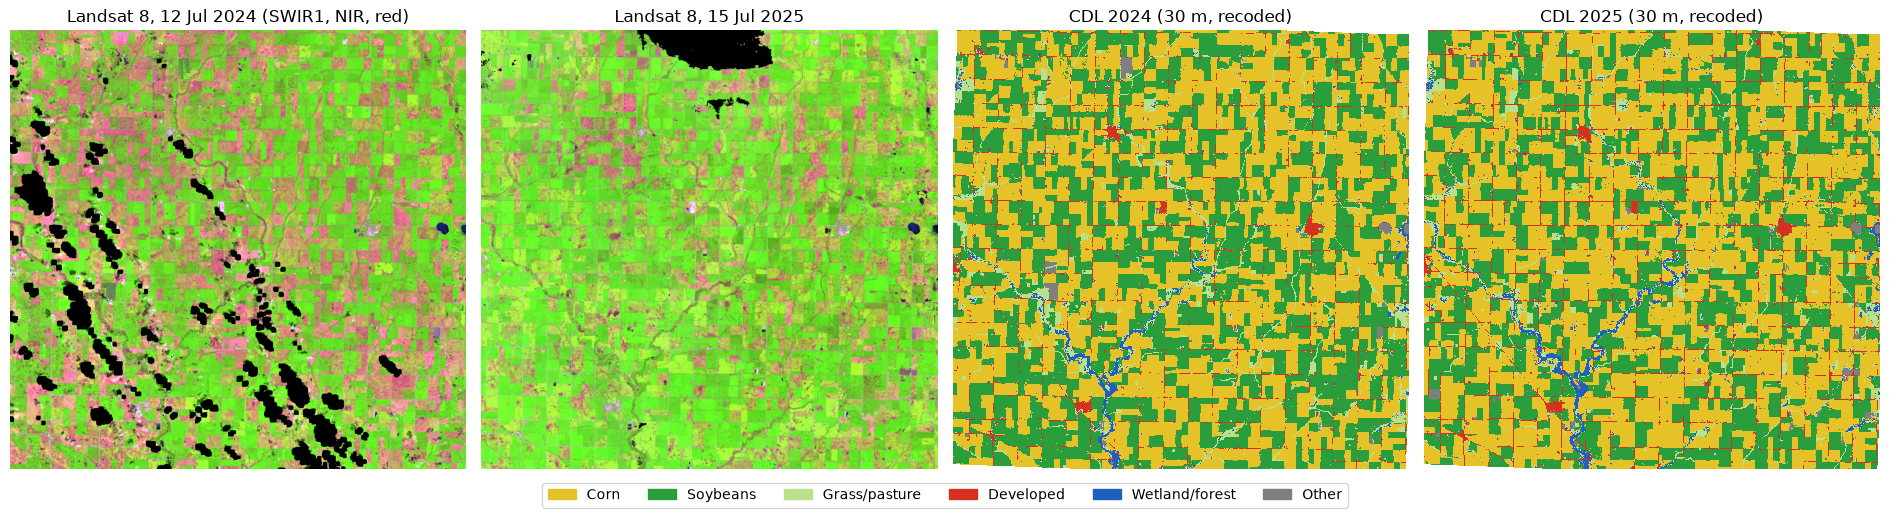

In [2]:
# one 30 m grid for everything: the Landsat grid (UTM 15N). Sentinel-2 is averaged onto it, CDL taken by nearest neighbour.
def folder(d, key):
    # the scene folder whose name contains key
    return next(p for p in d.iterdir() if p.is_dir() and key in p.name)

L_DATES = {"2021": "20210720", "2023": "20230710", "2024": "20240712", "2025": "20250715"}           # mid-July Landsat 8
# mid-July Sentinel-2 dates
S2_DATES = {"2020": "20200718", "2021": "20210720", "2022": "20220718", "2023": "20230710", "2024": "20240712", "2025": "20250714"}
# the 2024 Landsat red band as the 30 m reference grid
REF = rioxarray.open_rasterio(folder(L_DIR, L_DATES["2024"]) / "red.tif").squeeze(drop=True)
L_BANDS = ["blue", "green", "red", "nir", "swir16", "swir22"]  # the six shared bands
S2_EQUIV = {"blue": "blue", "green": "green", "red": "red", "nir": "nir08", "swir16": "swir16", "swir22": "swir22"}   # B8A ~ Landsat NIR

def landsat(key):  # one Landsat scene as reflectance on the grid
    p = folder(L_DIR, key)  # its folder
    # QA band as 16-bit integers
    qa = rioxarray.open_rasterio(p / "qa_pixel.tif").squeeze(drop=True).values.astype("uint16")
    # QA_PIXEL bits: 0 fill, 1 dilated cloud, 2 cirrus, 3 cloud, 4 cloud shadow
    bad = (qa & 0b11111) > 0
    # the six bands
    a = np.stack([rioxarray.open_rasterio(p / f"{b}.tif").squeeze(drop=True).values.astype("float32") for b in L_BANDS])
    a = np.where((a > 0) & ~bad[None], a * 2.75e-5 - 0.2, np.nan)          # Collection 2 surface reflectance
    # as a (band, y, x) DataArray
    return REF.expand_dims(band=L_BANDS).copy(data=a.astype("float32")).rename("reflectance")

def sentinel2(key):  # one Sentinel-2 scene averaged onto the 30 m grid
    p = folder(S2_DIR, key)  # its folder
    # scene classification on the grid
    scl = rioxarray.open_rasterio(p / "scl.tif").squeeze(drop=True).rio.reproject_match(REF, resampling=0).values
    bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11])  # no data, saturated, shadow, cloud, cirrus and snow
    # the equivalent bands, averaged onto 30 m, as reflectance
    a = np.stack([rioxarray.open_rasterio(p / f"{S2_EQUIV[b]}.tif", masked=True).squeeze(drop=True)
                  .rio.reproject_match(REF, resampling=5).values.astype("float32") * 1e-4 for b in L_BANDS])
    a = np.where(bad[None] | ~(a > 0), np.nan, a)  # flagged and non-positive values as missing
    # as a (band, y, x) DataArray
    return REF.expand_dims(band=L_BANDS).copy(data=a.astype("float32")).rename("reflectance")

CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
# CDL code -> class id
CODE_MAP = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4, 141: 4, 142: 4, 143: 4}
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # their colour map
def cdl(year):  # recoded CDL of one year on the grid
    # nearest-neighbour reprojection
    raw = rioxarray.open_rasterio(CDL_DIR / f"CDL_{year}_30m.tif").squeeze(drop=True).rio.reproject_match(REF, resampling=0).values
    lab = np.full(raw.shape, 5, "int16")  # everything else is "Other" (5)
    for k, v in CODE_MAP.items():  # the mapped codes ...
        lab[raw == k] = v  # ... get their class
    lab[raw == 0] = -1  # no data
    return lab  # the class map

t0 = time.time()  # start the timer
LS = {y: landsat(k) for y, k in L_DATES.items()}  # the four Landsat years
S2 = {y: sentinel2(k) for y, k in S2_DATES.items()}  # the six Sentinel-2 years
CDL = {y: cdl(y) for y in range(2020, 2026)}  # the CDL of 2020-2025
# time and grid
print(f"loaded in {time.time() - t0:.0f} s | grid {REF.shape[1]} x {REF.shape[0]} px at 30 m, {REF.rio.crs}")
print("masked (cloud/shadow/fill) share:",  # masked share of every image
      {f"Landsat {y}": f"{np.isnan(a.values[0]).mean():.2%}" for y, a in LS.items()},
      {f"S2 {y}": f"{np.isnan(a.values[0]).mean():.2%}" for y, a in S2.items()})

def rgb(a, lo=0.0, hi=0.12):  # true colour for display
    im = np.moveaxis(a.sel(band=["red", "green", "blue"]).values, 0, -1)  # red, green, blue with bands last
    return np.clip((np.nan_to_num(im) - lo) / (hi - lo), 0, 1) ** 0.8  # stretch, clip and brighten slightly
def fc(a):   # SWIR1, NIR, red: crops bright green, bare soil and built-up pink
    im = np.moveaxis(a.sel(band=["swir16", "nir", "red"]).values, 0, -1)  # SWIR 1, NIR, red with bands last
    return np.clip(np.nan_to_num(im) / np.array([0.35, 0.5, 0.15]), 0, 1)  # scaled per band

fig, ax = plt.subplots(1, 4, figsize=(19, 5))  # four panels
ax[0].imshow(fc(LS["2024"])); ax[0].set_title("Landsat 8, 12 Jul 2024 (SWIR1, NIR, red)")  # Landsat 2024
ax[1].imshow(fc(LS["2025"])); ax[1].set_title("Landsat 8, 15 Jul 2025")  # Landsat 2025
for a, y in zip(ax[2:], (2024, 2025)):  # CDL of both years
    # ...
    a.imshow(np.where(CDL[y] < 0, np.nan, CDL[y]), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); a.set_title(f"CDL {y} (30 m, recoded)")
for a in ax:  # every panel
    a.axis("off")  # no axes
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()  # arrange and draw

**A first look.** Even though the two images are three days apart in the calendar, they look different: in July 2024 many soybean fields are still pink in the SWIR-NIR-red composite (bare soil between the rows), while in July 2025 almost every field has a closed green canopy. The 2024 scene also has scattered cumulus clouds (6.8 % masked). In the CDL, corn and soybeans swap places in most fields: the rotation.


## Before you compare: co-registration and radiometric normalisation

### Co-registration with `check_coregistration`

A shift of a fraction of a pixel between the two dates turns every field edge into apparent change. `check_coregistration(reference, moving, band=)` estimates the shift by **phase cross-correlation**: the normalised cross-power spectrum of the two images,

$$
R(u,v)=\frac{F_1(u,v)\,F_2^{*}(u,v)}{\lvert F_1(u,v)\,F_2^{*}(u,v)\rvert}=e^{-2\pi i(u\,\Delta x+v\,\Delta y)},
$$

has an inverse Fourier transform that peaks at the shift $(\Delta x,\Delta y)$; up-sampling around the peak gives sub-pixel precision. A shift above `tolerance` (0.5 px) raises a warning. We check the Landsat pair, the cross-sensor pair, and a deliberately shifted copy.


warnings raised: ['images are misregistered by 1.10 px; co-register before change detecti']
                                                 dy   dx  error  magnitude
Landsat 2024 vs Landsat 2025 (same path/row)    0.0 -0.1    1.0        0.1
Sentinel-2 2025 vs Landsat 2025 (cross-sensor)  0.0  0.0    1.0        0.0
Landsat 2024 vs 2025 shifted by 1 px east       0.0 -1.1    1.0        1.1


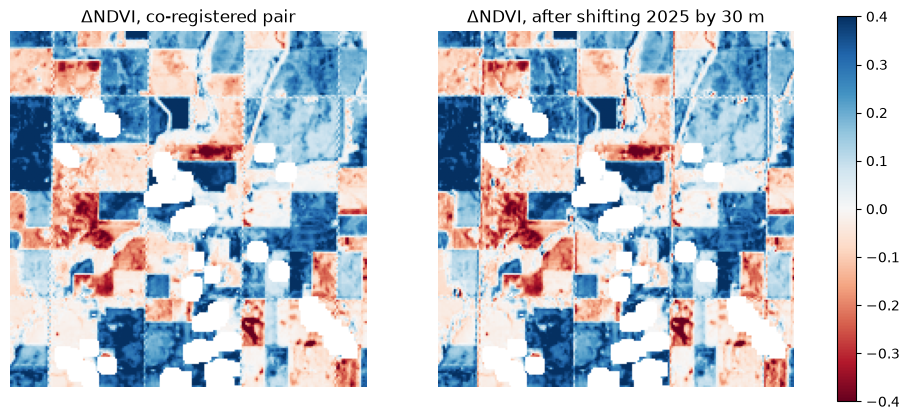

mean |ΔNDVI| on field-edge pixels: co-registered 0.130, shifted 0.138


In [3]:
B, A = LS["2024"], LS["2025"]                       # before, after
rows = {}  # one row per pair
with warnings.catch_warnings(record=True) as w:  # record warnings raised by the checks
    warnings.simplefilter("always")  # always show them
    # the same Landsat path/row in two years
    rows["Landsat 2024 vs Landsat 2025 (same path/row)"] = ic.check_coregistration(B, A, band="nir")
    # Sentinel-2 against Landsat
    rows["Sentinel-2 2025 vs Landsat 2025 (cross-sensor)"] = ic.check_coregistration(S2["2025"], A, band="nir")
    shifted = A.copy(data=np.roll(A.values, 1, axis=2))                         # a deliberate 1-pixel (30 m) shift
    # the deliberately shifted pair
    rows["Landsat 2024 vs 2025 shifted by 1 px east"] = ic.check_coregistration(B, shifted, band="nir")
    print("warnings raised:", [str(x.message)[:70] for x in w])  # warnings raised
print(pd.DataFrame(rows).T.round(3))  # offsets and correlation of each pair

# what misregistration does: NDVI difference of the true pair vs the pair with a 1-pixel shift
def ndvi(a):
    return (a.sel(band="nir") - a.sel(band="red")) / (a.sel(band="nir") + a.sel(band="red"))  # NDVI of an image
d_true, d_shift = ndvi(A) - ndvi(B), ndvi(shifted) - ndvi(B)  # NDVI change of the true and the shifted pair
z = (slice(450, 650), slice(450, 650))  # a 200 x 200 pixel zoom
fig, ax = plt.subplots(1, 2, figsize=(11, 5))  # two panels
# each version
for a_, d, t in zip(ax, (d_true, d_shift), ("ΔNDVI, co-registered pair", "ΔNDVI, after shifting 2025 by 30 m")):
    # the change map
    im = a_.imshow(d.values[z], cmap="RdBu", vmin=-0.4, vmax=0.4); a_.set_title(t); a_.axis("off")
plt.colorbar(im, ax=ax, fraction=0.03); plt.show()  # colour bar and draw
# field edges from the CDL
edge = ndi.binary_dilation(ndi.sobel(np.nan_to_num(CDL[2024].astype(float)), 1) != 0)
# mean change on field edges in both cases
print(f"mean |ΔNDVI| on field-edge pixels: co-registered {np.nanmean(np.abs(d_true.values[edge])):.3f}, "
      f"shifted {np.nanmean(np.abs(d_shift.values[edge])):.3f}")

The two Landsat dates (same path/row, Collection 2 geometry) agree to 0.1 px, and Sentinel-2 and Landsat on the 30 m grid too. The deliberate 30 m shift is detected (1.1 px) and triggers the warning. Its effect is visible as a thin line of false change along every field boundary; with this much real change, it adds only a little on average, but in a landscape with little true change it would dominate the change map.

### Radiometric normalisation with `histogram_match`

Surface-reflectance products are already corrected for the atmosphere, but residual differences remain (aerosols, view and sun angles, sensor). `histogram_match(image, reference)` maps each band of one date onto the cumulative distribution of the other,

$$
\rho'_{2}=F_{1}^{-1}\big(F_{2}(\rho_2)\big),
$$

with $F$ the empirical cumulative distribution function. This makes the two histograms identical, whether their differences come from the atmosphere or from **real change on the ground**. A useful check is a set of **pseudo-invariant features** (PIF): here, pixels that are built-up in both CDL years, whose reflectance should not change.


In [4]:
# radiometric normalisation: histogram_match maps each band of the 2025 image onto the 2024 distribution
A_hm = ic.histogram_match(A, B)
# pseudo-invariant features (PIF): pixels that are developed in both CDL years and far from fields; their
# reflectance should not change, so any difference is radiometric (atmosphere, sun, sensor)
pif = (CDL[2024] == 3) & (CDL[2025] == 3) & np.isfinite(B.values[0]) & np.isfinite(A.values[0])
pif = pif & ndi.binary_erosion((CDL[2024] == 3), iterations=1)  # drop built-up pixels next to other classes
rows = {}  # one row per band
for b in L_BANDS:  # each band
    # 2024, raw 2025 and matched 2025 values on the PIFs
    x, y_, yh = B.sel(band=b).values[pif], A.sel(band=b).values[pif], A_hm.sel(band=b).values[pif]
    # PIF and scene means
    rows[b] = {"2024 PIF mean": x.mean(), "2025 PIF mean (raw)": y_.mean(), "2025 PIF mean (histogram-matched)": yh.mean(),
               "scene mean 2024": np.nanmean(B.sel(band=b).values), "scene mean 2025 (raw)": np.nanmean(A.sel(band=b).values)}
print(f"{pif.sum():,} pseudo-invariant (built-up) pixels")  # number of PIF pixels
pd.DataFrame(rows).T.round(4)  # as a table

2,977 pseudo-invariant (built-up) pixels


,2024 PIF mean,2025 PIF mean (raw),2025 PIF mean (histogram-matched),scene mean 2024,scene mean 2025 (raw)
blue,0.0651,0.0672,0.0749,0.0358,0.0301
green,0.1098,0.1130,0.1231,0.0597,0.0558
red,0.1115,0.1129,0.1280,0.0455,0.0381
nir,0.3429,0.3477,0.2833,0.3618,0.4124
swir16,0.2599,0.2563,0.2908,0.2088,0.1893
swir22,0.1814,0.1732,0.2240,0.1234,0.0964


**Reading the check.** On the built-up PIFs, the raw 2025 reflectance is already within a few per cent of 2024 in every band: the Collection 2 surface reflectance is consistent between the two dates. Histogram matching moves the PIFs **away** from their 2024 values (NIR from 0.348 to 0.283, SWIR-2 from 0.173 to 0.224), because the scene histograms differ for a real reason: the 2025 crops were more developed (scene NIR 0.41 vs 0.36). Histogram matching is the right tool when the two images are dominated by the same unchanged surfaces, or between sensors; when a large part of the scene really changes, it distorts the radiometry. We therefore keep the raw reflectance for the classical methods and test histogram matching as an option (see *Classical methods: difference, ratio, change vector analysis, PCA and thresholds*) and for the cross-sensor deep models (see *Deep change detection: Siamese, early-fusion and transformer networks*).


## Classical methods: difference, ratio, change vector analysis, PCA and thresholds

For two co-registered images $\mathbf x_1,\mathbf x_2$ (vectors of $B$ bands per pixel):

- **Image difference** (`image_difference`): $d=x_2-x_1$ of one band or index (here NDVI). Change is flagged where $d$ leaves the bulk of the distribution, $d>\mu+k\sigma$ (increase) or $d<\mu-k\sigma$ (decrease).
- **Image ratio** (`image_ratio`, log ratio): $r=\ln\frac{x_2}{x_1}$, symmetric for increases and decreases and insensitive to multiplicative effects (preferred for SAR). Here on NIR.
- **Change vector analysis** (`change_vector_analysis`, `classify.cva`): the change vector $\Delta\mathbf x=\mathbf x_2-\mathbf x_1$ has a **magnitude** $\lVert\Delta\mathbf x\rVert=\sqrt{\sum_b\Delta x_b^2}$ (how much changed) and, in a two-band plane, a **direction** $\theta=\operatorname{atan2}(\Delta x_{b_2},\Delta x_{b_1})$ (what kind of change).
- **PCA change** (`pca_change`): PCA of the standardised **stacked** bands $[\mathbf x_1;\mathbf x_2]$ (the first components carry the stable structure, later ones the change), or of the **difference** image, where $\lvert\mathrm{PC}_1\rvert$ is the main change signal.

**Thresholds.** The ±$k\sigma$ rule assumes change is a small tail of a mostly unchanged distribution. **Otsu's method** (chapter 01, `ip.threshold(img, "otsu")`) instead picks the threshold $t$ that maximises the between-class variance of the two groups it creates,

$$
t^{*}=\arg\max_t\ \omega_0(t)\,\omega_1(t)\,\big(\mu_0(t)-\mu_1(t)\big)^2 ,
$$

which works whatever the proportion of change, as long as the histogram is bimodal. Each mask is scored against the CDL change with `change_metrics` (the *Evaluation: change metrics and area-adjusted change area* section explains the metrics).


In [5]:
# Reference for this section: a pixel "changed" when its CDL class differs between 2024 and 2025
valid = (CDL[2024] >= 0) & (CDL[2025] >= 0) & np.isfinite(B.values).all(0) & np.isfinite(A.values).all(0)
# 1 = class changed, 0 = unchanged, NaN = not usable
ref = np.where(valid, (CDL[2024] != CDL[2025]).astype(float), np.nan)
# share of changed pixels
print(f"reference: {np.nanmean(ref):.1%} of the valid pixels change class between 2024 and 2025 (mostly corn <-> soybean)")
METHODS, SCORES = {}, {}  # change masks and their scores

def score(name, mask):  # store a change mask and score it against the reference
    METHODS[name] = np.asarray(mask).astype(bool) & valid  # the mask on usable pixels
    SCORES[name] = ic.change_metrics(METHODS[name], ref)  # precision, recall, F1, IoU, accuracy and kappa

nB, nA = ndvi(B), ndvi(A)  # NDVI before and after
# 1. image difference (NDVI): +/- k sigma flags, and Otsu on |difference| (image_processing.threshold, chapter 01)
dif = ic.image_difference(nB, nA, k=2.0)
score("NDVI difference, ±2σ", dif["increase"] | dif["decrease"])  # increase or decrease beyond 2 SD
# Otsu threshold on the absolute difference
otsu_mask, t_d = ip.threshold(np.abs(dif["difference"]).expand_dims(band=[1]), "otsu", return_value=True)
score(f"NDVI difference, Otsu |Δ| > {t_d[0]:.3f}", np.asarray(otsu_mask).squeeze())  # score it
# 2. log ratio (NIR)
rat = ic.image_ratio(B.sel(band="nir"), A.sel(band="nir"), log=True, k=2.0)
score("NIR log ratio, ±2σ", rat["increase"] | rat["decrease"])  # increase or decrease beyond 2 SD
# Otsu on the absolute log ratio
m_r, t_r = ip.threshold(np.abs(rat["ratio"]).expand_dims(band=[1]), "otsu", return_value=True)
score(f"NIR log ratio, Otsu |ln r| > {t_r[0]:.3f}", np.asarray(m_r).squeeze())  # score it
# 3. change vector analysis on all six bands (Otsu on the magnitude), raw and after histogram matching
cv = ic.change_vector_analysis(B, A)
score(f"CVA, 6 bands, Otsu ({cv.attrs['threshold']:.3f})", cv["change"])  # Otsu on the CVA magnitude
cv_hm = ic.change_vector_analysis(B, A_hm)  # CVA after histogram matching
score(f"CVA after histogram_match ({cv_hm.attrs['threshold']:.3f})", cv_hm["change"])  # score it
# 4. PCA: of the difference image (Otsu on |PC1|) and of the stacked bands (inspect the components)
pcd = ic.pca_change(B, A, method="difference")
# Otsu on |PC1| of the difference
score(f"PCA of the difference, Otsu |PC1| > {pcd.attrs['threshold']:.2f}", pcd["change"])
pcs = ic.pca_change(B, A, method="stacked")  # PCA of the stacked bands
# explained variance of the components
print("stacked PCA, explained variance of PC1-PC6:", np.round(pcs.attrs["explained_variance_ratio"][:6], 3))
# scores of all methods
classical = pd.DataFrame(SCORES).T[["precision", "recall", "f1", "iou", "overall_accuracy", "kappa"]].round(3)
# share of pixels flagged by each
classical["mapped change (%)"] = [METHODS[k][valid].mean() * 100 for k in classical.index]
classical.round(3)  # show them

reference: 79.2% of the valid pixels change class between 2024 and 2025 (mostly corn <-> soybean)


stacked PCA, explained variance of PC1-PC6: [0.496 0.335 0.08  0.035 0.024 0.01 ]


,precision,recall,f1,iou,overall_accuracy,kappa,mapped change (%)
"NDVI difference, ±2σ",0.971,0.052,0.098,0.052,0.248,0.020,4.210
"NDVI difference, Otsu |Δ| > 0.176",0.964,0.434,0.599,0.427,0.539,0.210,35.668
"NIR log ratio, ±2σ",0.919,0.052,0.099,0.052,0.246,0.015,4.519
"NIR log ratio, Otsu |ln r| > 0.315",0.939,0.376,0.537,0.367,0.487,0.154,31.686
"CVA, 6 bands, Otsu (0.172)",0.970,0.513,0.671,0.505,0.602,0.273,41.892
CVA after histogram_match (0.175),0.975,0.629,0.765,0.619,0.694,0.379,51.113
"PCA of the difference, Otsu |PC1| > 2.00",0.977,0.601,0.744,0.592,0.673,0.355,48.658


**Reading the classical results.**

- **±2σ thresholds fail completely** (recall 0.05): 79 % of the pixels change, so change is not a tail of the distribution. The rule finds only the most extreme 4 to 5 % of the pixels.
- **Otsu thresholds** are much better, with high precision (0.94 to 0.98) everywhere: what they flag as change is change. But **recall stays low** (0.37 to 0.63): many rotated fields have a similar July spectrum in both years (a mid-July corn canopy and a mid-July soybean canopy are both green), and the seasonal shift between the years blurs the bimodal histogram.
- **Multi-band methods beat single indices**: CVA on six bands (F1 0.67) and PCA of the difference (0.74) beat NDVI (0.60) and NIR (0.54), because corn and soybeans differ more in SWIR than in NDVI.
- **Histogram matching helps CVA** (F1 0.67 → 0.77), despite distorting the PIFs: it removes the shared seasonal shift (2025 greener everywhere), which otherwise inflates the change magnitude of *unchanged* fields and hides the crop swap. Normalisation can help detection and hurt radiometry at the same time.


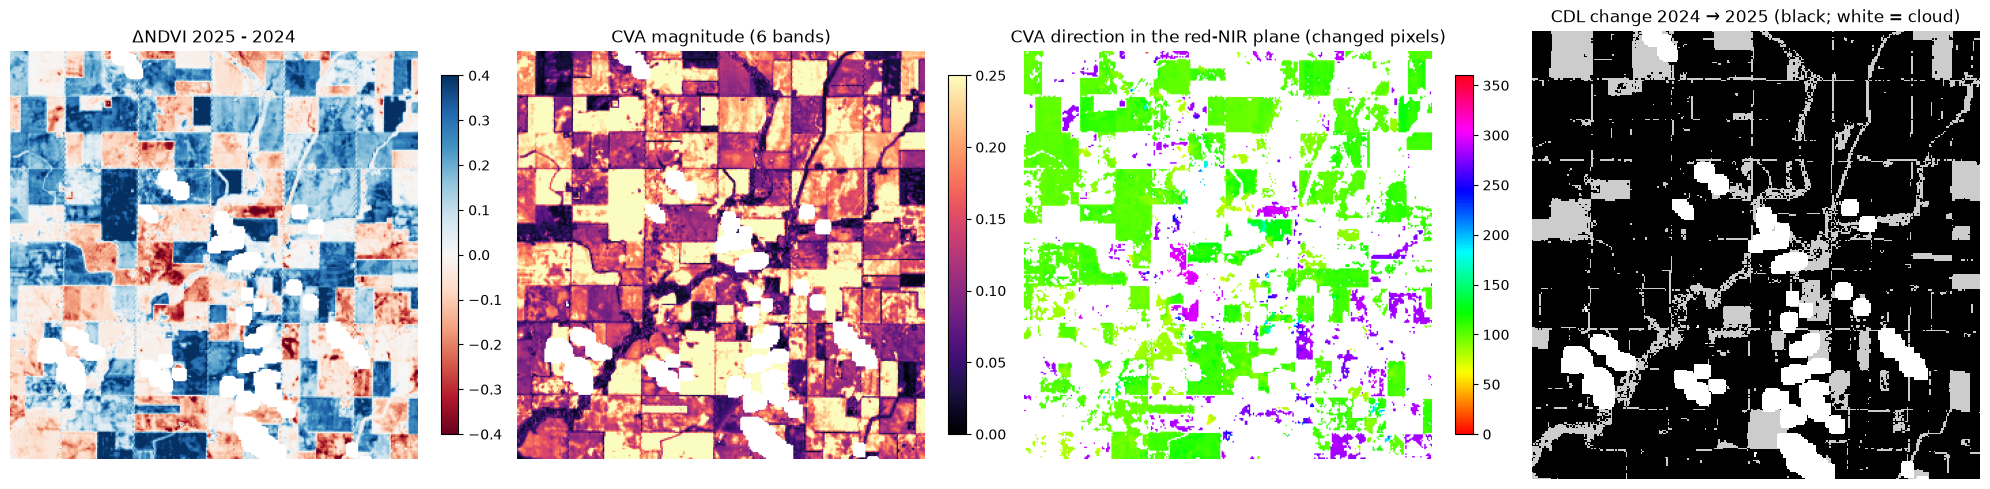

median CVA direction (degrees, red-NIR plane): {'corn → soybeans': 283.0, 'soybeans → corn': 105.0, 'corn → corn': 94.0, 'soybeans → soybeans': 106.0}


In [6]:
# CVA in the red-NIR plane with classify.cva: the direction tells WHAT kind of change happened
cv2 = classify.cva(B.sel(band=["red", "nir"]).to_dataset("band"), A.sel(band=["red", "nir"]).to_dataset("band"), bands=["red", "nir"])
z = (slice(400, 700), slice(380, 680))  # a 300 x 300 pixel zoom
trans = np.where(valid, CDL[2024] * 10 + CDL[2025], -1)  # from-to code (2024 class x 10 + 2025 class)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))  # four panels
# NDVI change
im = ax[0].imshow(np.where(valid, dif["difference"].values, np.nan)[z], cmap="RdBu", vmin=-0.4, vmax=0.4); ax[0].set_title("ΔNDVI 2025 - 2024")
plt.colorbar(im, ax=ax[0], fraction=0.04)  # colour bar
# CVA magnitude
im = ax[1].imshow(np.where(valid, cv["magnitude"].values, np.nan)[z], cmap="magma", vmin=0, vmax=0.25); ax[1].set_title("CVA magnitude (6 bands)")
plt.colorbar(im, ax=ax[1], fraction=0.04)  # colour bar
# CVA direction of changed pixels
im = ax[2].imshow(np.where(valid & (cv2["change"].values), cv2["direction"].values, np.nan)[z], cmap="hsv", vmin=0, vmax=360)
# title and colour bar
ax[2].set_title("CVA direction in the red-NIR plane (changed pixels)"); plt.colorbar(im, ax=ax[2], fraction=0.04)
ax[3].imshow(np.where(valid, ref, np.nan)[z], cmap=ListedColormap(["#cccccc", "black"]), vmin=-0.5, vmax=1.5, interpolation="nearest")
ax[3].set_title("CDL change 2024 → 2025 (black; white = cloud)")  # title
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw
# direction and transition of every usable pixel
dirs = pd.DataFrame({"direction": cv2["direction"].values[valid], "t": trans[valid]})
lab = {0: "corn → soy", 10: "soy → corn"}  # names of two transitions
print("median CVA direction (degrees, red-NIR plane):",  # median direction per transition
      {"corn → soybeans": round(float(dirs[dirs.t == 1].direction.median()), 0), "soybeans → corn": round(float(dirs[dirs.t == 10].direction.median()), 0),
       "corn → corn": round(float(dirs[dirs.t == 0].direction.median()), 0), "soybeans → soybeans": round(float(dirs[dirs.t == 11].direction.median()), 0)})

**CVA direction tells the kind of change.** In the red-NIR plane, corn → soybean pixels change in a direction of about 283° (less NIR in mid-July 2025, the young soybean canopy) and soybean → corn pixels at about 105° (more NIR). But soybean → soybean pixels also point at about 106°: the 2025 soybeans were further developed than the 2024 ones, so an unchanged crop can look like a change. Without labels, the direction alone cannot separate a crop swap from a phenology shift.


## Post-classification change: the from-to matrix

Post-classification comparison classifies each date **independently** and compares the maps. Its strength is that it says *from what to what*; its weakness is that the errors of both maps add up. `classify.post_classification(map1, map2, labels=, pixel_area=)` returns a transition raster (code $= 1000\cdot\text{from}+\text{to}$) and the **from-to matrix** in area units.

To keep the maps independent of the reference, a Random Forest is trained on the Landsat July images of **2021 and 2023** with their CDL, and applied to 2024 and 2025.


In [7]:
from sklearn.ensemble import RandomForestClassifier  # random forest
# Classify each July Landsat image with a Random Forest trained on OTHER years (2021 and 2023 with their CDL),
# so the 2024 and 2025 maps are independent of the CDL they are compared with.
def features(a):
    x = a.values  # the image values
    nd = lambda i, j: (x[i] - x[j]) / (x[i] + x[j] + 1e-6)  # normalised difference of two bands
    f = np.concatenate([x, nd(3, 2)[None], nd(3, 4)[None], nd(1, 3)[None]])      # bands, NDVI, NDMI, NDWI
    return f.reshape(f.shape[0], -1).T  # one row per pixel
Xtr, ytr = [], []  # training features and labels
for y in ("2021", "2023"):  # two training years
    f, l = features(LS[y]), CDL[int(y)].ravel()  # features and labels of that year
    ok = np.isfinite(f).all(1) & (l >= 0)  # complete and labelled pixels
    idx = rng.choice(np.flatnonzero(ok), 60_000, replace=False)  # 60,000 random pixels
    Xtr.append(f[idx]); ytr.append(l[idx])  # keep them
t0 = time.time()  # start the timer
# a class-balanced random forest
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, min_samples_leaf=2, class_weight="balanced_subsample")
rf.fit(np.concatenate(Xtr), np.concatenate(ytr))  # fit on 2021 and 2023
MAPS = {}  # maps per year
for y in ("2024", "2025"):  # the two test years
    f = features(LS[y]); ok = np.isfinite(f).all(1)  # features and complete pixels
    m = np.full(f.shape[0], -1, "int16"); m[ok] = rf.predict(f[ok])  # classify the complete pixels
    MAPS[int(y)] = m.reshape(REF.shape)  # as a map
    lab = CDL[int(y)]; v = (MAPS[int(y)] >= 0) & (lab >= 0)  # the CDL and comparable pixels
    print(f"Landsat map {y} vs CDL {y}: OA {(MAPS[int(y)][v] == lab[v]).mean():.3f}")  # agreement with the CDL
print(f"Random Forest trained on Landsat July 2021 + 2023 in {time.time() - t0:.0f} s")  # time taken

labels = dict(enumerate(CLASSES))  # class id -> name
# from-to analysis of the two Landsat maps (30 m pixel = 0.09 ha)
tr_map, ft_map = classify.post_classification(REF.copy(data=np.where(valid, MAPS[2024], -1)), REF.copy(data=np.where(valid, MAPS[2025], -1)),
                                               labels=labels, pixel_area=0.09)          # 30 m pixel = 0.09 ha
# the same for the two CDL years
tr_cdl, ft_cdl = classify.post_classification(REF.copy(data=np.where(valid, CDL[2024], -1)), REF.copy(data=np.where(valid, CDL[2025], -1)),
                                               labels=labels, pixel_area=0.09)
# score map change against CDL change
score("Post-classification (Landsat RF maps 2024, 2025)", (MAPS[2024] != MAPS[2025]) & (MAPS[2024] >= 0) & (MAPS[2025] >= 0))
# header and table
print("\nFrom-to matrix, Landsat maps (ha, rows = 2024, columns = 2025):"); print(ft_map.round(0).astype(int))
print("\nFrom-to matrix, CDL (ha):"); print(ft_cdl.round(0).astype(int))  # header and table
# scores
print("\npost-classification change vs CDL change:", {k: round(v, 3) for k, v in SCORES["Post-classification (Landsat RF maps 2024, 2025)"].items()})

Landsat map 2024 vs CDL 2024: OA 0.804


Landsat map 2025 vs CDL 2025: OA 0.872
Random Forest trained on Landsat July 2021 + 2023 in 12 s

From-to matrix, Landsat maps (ha, rows = 2024, columns = 2025):
to               Corn  Soybeans  Grass/pasture  Developed  Wetland/forest  \
from                                                                        
Corn             7158     22256            305        158             204   
Soybeans        27359      4597           1590        883            1188   
Grass/pasture     868      2260           2241        193             135   
Developed         775       912            243       3022              31   
Wetland/forest    581      1143            262         38             282   
Other             425       183            104         80              49   

to              Other  
from                   
Corn               64  
Soybeans          223  
Grass/pasture      66  
Developed          27  
Wetland/forest     33  
Other             152  

From-to matrix, CDL (ha):
to

**Reading the from-to matrices.** Both are dominated by the off-diagonal corn ↔ soybean cells: the rotation is the main "change" of this landscape, and post-classification reproduces it (F1 of the change class 0.91, the best so far). But the matrices also show the price of two independent maps: the Landsat maps put about 1 600 ha into soybean → grass/pasture and 1 100 ha into soybean → wetland/forest, against 150 ha and 27 ha in the CDL. Most of these are classification errors in one of the two years, which become **false change**. With per-map accuracies of $a_1$ and $a_2$, roughly $1-a_1a_2$ of the pixels can carry an error in at least one map, which here (0.80 and 0.87) is up to 30 %.


## The CDL as reference: what counts as true change?

Every score above uses the CDL as truth. The CDL is itself a classification, made independently every year: in Iowa NASS reports accuracies of roughly 95 % or more for corn and soybeans, and much lower for minor classes such as grass/pasture. Its **change** inherits the errors of both years. We look at how much the CDL changes, of what kind, and where.


             changed (%)  corn ↔ soybean rotation (%)  other change (%)
pair                                                                   
2020 → 2021         76.0                         73.0               3.0
2021 → 2022         78.2                         76.5               1.8
2022 → 2023         78.8                         77.2               1.6
2023 → 2024         81.7                         76.1               5.7
2024 → 2025         79.4                         74.2               5.2

2024 → 2025 CDL transitions (% of valid pixels):
no change                       20.82
corn ↔ soybean rotation         74.00
other change at a field edge     4.76
other change inside a field      0.42
dtype: float64



corn (C) / soybean (S) sequences 2023-2024-2025, % of all-crop pixels:
CSC    43.9
SCS    36.4
CCC     8.3
SCC     6.2
CCS     3.6
CSS     0.6
SSC     0.6
SSS     0.4


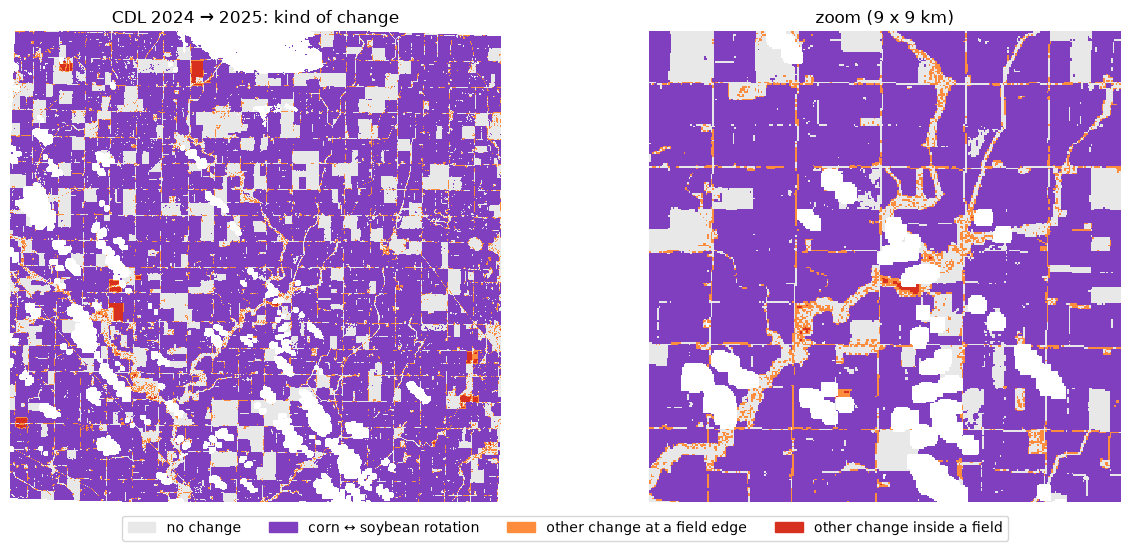

interior pixels (no class boundary in 2024 or 2025): 70.2% of the valid pixels; change in the interior: 84.1%


In [8]:
# Year-to-year CDL change, 2020 -> 2025: how much changes, and of what kind?
lv = lambda y1, y2: (CDL[y1] >= 0) & (CDL[y2] >= 0)
rows = []  # one row per pair of years
for y in range(2020, 2025):  # each pair
    v = lv(y, y + 1)  # pixels labelled in both
    a, b = CDL[y][v], CDL[y + 1][v]  # classes in both years
    rot = ((a == 0) & (b == 1)) | ((a == 1) & (b == 0))  # corn-soybean switches
    # changed share, rotation and other change
    rows.append({"pair": f"{y} → {y + 1}", "changed (%)": (a != b).mean() * 100, "corn ↔ soybean rotation (%)": rot.mean() * 100,
                 "other change (%)": ((a != b) & ~rot).mean() * 100})
print(pd.DataFrame(rows).set_index("pair").round(1))  # show them

# What counts as true change? Classify every 2024 -> 2025 CDL transition
def boundary(lab):
    # pixels touching a different class (4-neighbourhood): mixed field-edge pixels at 30 m
    return ((ndi.maximum_filter(lab, 3) != lab) | (ndi.minimum_filter(lab, 3) != lab))
edge = boundary(CDL[2024]) | boundary(CDL[2025])  # field edges in either year
a, b = CDL[2024], CDL[2025]  # the two years
rot = ((a == 0) & (b == 1)) | ((a == 1) & (b == 0))  # rotation
other = (a != b) & ~rot  # other changes
cat = np.full(a.shape, -1, "int8")  # -1 = not usable
cat[valid & (a == b)] = 0  # 0 = no change
cat[valid & rot] = 1  # 1 = rotation
cat[valid & other & edge] = 2  # 2 = other change at a field edge
cat[valid & other & ~edge] = 3  # 3 = other change inside a field
# category names
CAT = ["no change", "corn ↔ soybean rotation", "other change at a field edge", "other change inside a field"]
share = pd.Series(cat[valid]).value_counts(normalize=True).sort_index() * 100  # share of each category
# header and shares
print("\n2024 → 2025 CDL transitions (% of valid pixels):"); print(pd.Series(share.values, index=[CAT[i] for i in share.index]).round(2))

# a rotation should alternate: corn-soy-corn or soy-corn-soy over 2023-2025; breaks are either real decisions
# (corn on corn, soy on soy) or label noise
c3 = (CDL[2023] >= 0) & valid
seq = pd.Series(list(zip(CDL[2023][c3], a[c3], b[c3])))  # class triplets 2023-2024-2025
crop3 = seq.apply(lambda t: all(v in (0, 1) for v in t))  # pixels that were corn or soybeans in all three years
# C/S pattern shares
pat = seq[crop3].apply(lambda t: "".join("CS"[v] for v in t)).value_counts(normalize=True) * 100
# header and table
print("\ncorn (C) / soybean (S) sequences 2023-2024-2025, % of all-crop pixels:"); print(pat.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))  # two panels
z = (slice(400, 700), slice(380, 680))  # a 300 x 300 pixel zoom
ccol = ListedColormap(["#e8e8e8", "#7f3fbf", "#fd8d3c", "#d7301f"])
# the categories
ax[0].imshow(np.where(cat < 0, np.nan, cat), cmap=ccol, vmin=-0.5, vmax=3.5, interpolation="nearest"); ax[0].set_title("CDL 2024 → 2025: kind of change")
# zoom
ax[1].imshow(np.where(cat < 0, np.nan, cat)[z], cmap=ccol, vmin=-0.5, vmax=3.5, interpolation="nearest"); ax[1].set_title("zoom (9 x 9 km)")
for a_ in ax:  # every panel
    a_.axis("off")  # no axes
# category legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ccol.colors], labels=CAT, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()  # arrange and draw
# the evaluation masks used from here on: all valid pixels, and "interior" pixels away from any class boundary
interior = valid & ~edge
# interior share and change share there
print(f"interior pixels (no class boundary in 2024 or 2025): {interior.sum() / valid.sum():.1%} of the valid pixels; "
      f"change in the interior: {np.nanmean(ref[interior]):.1%}")

**Reading the CDL change.**

- About **76 to 82 %** of the pixels change class every year, and almost all of it is the **corn ↔ soybean rotation** (73 to 77 %). The rotation is real, planned and annual: for most applications (yield statistics, nitrogen) it *is* the change of interest; for land-cover change (cropland lost to development, grassland converted to crops) it is "no change".
- **Other change** is 2 to 6 % per year, and in 2024 → 2025 92 % of it lies on a **field edge** (a pixel touching another class): mixed 30 m pixels and slightly different field boundaries in the two years, not land conversion. Only 0.4 % of the pixels show other change inside a field. The 2023 → 2024 and 2024 → 2025 pairs have about twice as much other change as earlier pairs, possibly a change in the CDL production (a 10 m CDL is available from 2024 on).
- **Sequences:** 80 % of the crop pixels follow a strict alternation in 2023 to 2025 (CSC or SCS); 8 % stay corn (corn on corn is a real practice); the rare SSC, CSS and SSS patterns are partly real decisions and partly label noise.
- From here on we report every score on **all** valid pixels and on **interior** pixels (no class boundary in either year, 70 % of the pixels), where the CDL change is much more reliable.


## Deep change detection: Siamese, early-fusion and transformer networks

`build_change_model(arch, in_channels, num_classes)` returns a network with `forward(t1, t2)` → per-pixel change logits:

- **Early-fusion U-Net** (FC-EF, Daudt et al., 2018): the two images are concatenated as $2C$ input channels and a single U-Net predicts change. Simple, but the network must learn on its own which channels belong to which date.
- **Siamese-difference U-Net** (FC-Siam-diff): a **shared** encoder $f_\theta$ processes each date; the decoder receives the absolute difference of the features at every scale, $\lvert f_\theta^{(l)}(\mathbf x_1)-f_\theta^{(l)}(\mathbf x_2)\rvert$. Weight sharing makes the two dates comparable by construction.
- **Siamese-concatenation U-Net** (FC-Siam-conc): the same shared encoder, but the features of both dates are concatenated, $[f^{(l)}(\mathbf x_1);f^{(l)}(\mathbf x_2)]$, so the decoder can learn asymmetric (from-to) changes.
- **BIT-style transformer** (after Chen et al., 2021): a shared CNN extracts features; spatial attention compresses each date into a few **semantic tokens**, $T=\mathrm{softmax}(A(f))\,f^\top$; a transformer encoder models the joint context of the tokens of both dates; a transformer decoder projects the tokens back onto the pixels, and the absolute difference of the refined features is classified.

`PairChipDataset(before, after, masks, normalizer=, transform=)` yields `{"image": (t1, t2), "mask": change}`; the transform (`OverheadAugment`, dihedral rotations and flips) is applied **identically** to both dates and the mask. Training uses `train_model(task="segmentation")` with cross-entropy, `ignore_index=-100` for pixels without a reference, and early stopping on the 2023 → 2024 validation pair.

The networks are trained on **Sentinel-2** pairs of earlier years, reduced to the six Landsat-equivalent bands, so they can also be applied to the Landsat test pair. The normaliser is fitted on the Sentinel-2 images of 2020 to 2023 only.


In [9]:
# Deep change detection is supervised: it learns from image pairs with change masks. We train on Sentinel-2
# July pairs of earlier years (averaged to 30 m, the six Landsat-equivalent bands) and keep 2024 -> 2025 for test.
PAIRS = {"train": [("2020", "2021"), ("2021", "2022"), ("2022", "2023")], "val": [("2023", "2024")], "test": [("2024", "2025")]}

def change_mask(y1, y2, a1, a2):  # CDL change mask of a pair: 1 changed, 0 unchanged, -100 ignored
    # pixels usable in both years and both images
    ok = (CDL[int(y1)] >= 0) & (CDL[int(y2)] >= 0) & np.isfinite(a1.values).all(0) & np.isfinite(a2.values).all(0)
    return np.where(ok, (CDL[int(y1)] != CDL[int(y2)]).astype("int64"), -100)  # the mask

# per-band z-score from the training-year images
NORM = ic.Normalizer("zscore").fit(np.concatenate([S2[y].values.reshape(len(L_BANDS), -1) for y in ("2020", "2021", "2022", "2023")], 1).T)
SIZE, STRIDE = 64, 32  # 64 px chips, 32 px stride
H, W = REF.shape  # grid size
# every chip corner
starts = [(r, c) for r in range(0, H - SIZE + 1, STRIDE) for c in range(0, W - SIZE + 1, STRIDE)]
def chips(pairs):  # chip pairs and masks of a list of year pairs
    t1, t2, m = [], [], []  # lists
    for y1, y2 in pairs:  # each year pair
        a1, a2 = S2[y1], S2[y2]  # the two images
        cm = change_mask(y1, y2, a1, a2)  # their change mask
        for r, c in starts:  # every chip position
            sl = (slice(r, r + SIZE), slice(c, c + SIZE))  # the window
            if (cm[sl] >= 0).mean() < 0.5:  # skip chips less than half usable
                continue
            # keep both chips and the mask
            t1.append(a1.values[(slice(None),) + sl]); t2.append(a2.values[(slice(None),) + sl]); m.append(cm[sl])
    return np.stack(t1), np.stack(t2), np.stack(m)  # as arrays

CH = {k: chips(v) for k, v in PAIRS.items()}  # chips of every split
for k, (a, b, m) in CH.items():  # each split
    # chip count, size and change share
    print(f"{k:5s}: {len(a):4d} chip pairs of {SIZE} x {SIZE} px ({SIZE * 30 / 1000:.1f} km), change share {(m == 1).sum() / (m >= 0).sum():.1%}")
aug = ic.OverheadAugment(dihedral=True, p=1.0, seed=SEED)            # the same rotation/flip for both dates and the mask
ds_tr = ic.PairChipDataset(*CH["train"], normalizer=NORM, transform=aug)  # training pairs with augmentation
ds_va = ic.PairChipDataset(*CH["val"], normalizer=NORM)  # validation pairs
item = ds_tr[0]  # one item
# its shapes
print("PairChipDataset item:", {k: (tuple(v[0].shape), tuple(v[1].shape)) if k == "image" else tuple(v.shape) for k, v in item.items()})

train: 2610 chip pairs of 64 x 64 px (1.9 km), change share 77.7%
val  :  867 chip pairs of 64 x 64 px (1.9 km), change share 81.7%
test :  867 chip pairs of 64 x 64 px (1.9 km), change share 79.1%


PairChipDataset item: {'image': ((6, 64, 64), (6, 64, 64)), 'mask': (64, 64)}


In [10]:
# four change architectures
ARCHS = {"Siamese-diff U-Net": ("siamese_diff", {}), "Siamese-concat U-Net": ("siamese_concat", {}),
         "Early-fusion U-Net": ("early_fusion", {}), "BIT-style transformer": ("bit", {"dim": 32, "n_tokens": 4})}
DEEP, HIST = {}, {}  # models and histories
rows = []  # one row per model
for name, (arch, kw) in ARCHS.items():  # each architecture
    # build it for six bands and two classes
    m = ic.build_change_model(arch, in_channels=len(L_BANDS), num_classes=2, **kw)
    t0 = time.time()  # start the timer
    # train in segmentation mode, ignoring -100 pixels
    h = ic.train_model(m, ic.as_loader(ds_tr, 16, shuffle=True, seed=SEED), ic.as_loader(ds_va, 32, shuffle=False),
                       task="segmentation", epochs=EPOCHS, loss="ce", optimizer="adamw", lr=1e-3, scheduler="cosine",
                       early_stopping=8, monitor="val_score", num_classes=2, ignore_index=-100, device=DEVICE, seed=SEED, verbose=False)
    DEEP[name], HIST[name] = m, h  # keep model and history
    # size, epochs, accuracy and time
    rows.append({"model": name, "parameters": ic.count_parameters(m), "epochs run": len(h["val_score"]),
                 "best val mIoU (2023 → 2024)": max(h["val_score"]), "seconds": round(time.time() - t0)})
pd.DataFrame(rows).set_index("model").round(3)  # as a table

,parameters,epochs run,best val mIoU (2023 → 2024),seconds
model,,,,
Siamese-diff U-Net,483186,22,0.795,64
Siamese-concat U-Net,564338,29,0.791,80
Early-fusion U-Net,484050,14,0.771,28
BIT-style transformer,70022,29,0.797,172


All four networks reach a validation mean IoU of about 0.78 to 0.80 on the 2023 → 2024 pair. The BIT-style model has a seventh of the parameters of the U-Nets.

### Predicting the test pair, and crossing sensors

The networks are applied in the 64 × 64 px tiles they were trained on (50 % overlap, averaged); tiling is necessary for the transformer, whose decoder attends between all pixel positions of its input, which is quadratic in the image size. We predict the Sentinel-2 test pair, and the **Landsat** test pair in three versions:

- **raw** Landsat reflectance;
- **cross-calibrated**: a linear gain and offset per band fitted on the same-day pair of 10 July 2023 (the approach of harmonised products such as HLS); Sentinel-2 L2A is 10 to 40 % brighter than Landsat Collection 2 in this pair;
- **histogram-matched** onto the Sentinel-2 image of 2023 (a training-year image), with `histogram_match`.


In [11]:
# change probability for a whole image pair
def predict_full(model, a1, a2, tile=SIZE, stride=SIZE // 2, batch=64):
    """Change probability for a whole image pair, predicted in the 64 x 64 px tiles the models were trained on
    (50 % overlap, overlapping predictions averaged). Tiling also keeps the memory of the transformer bounded:
    its decoder attends between all pixel positions of the input, which is quadratic in the image size."""
    x1 = np.nan_to_num(NORM.transform(a1.values[None], 1))[0].astype("float32")  # normalised first date
    x2 = np.nan_to_num(NORM.transform(a2.values[None], 1))[0].astype("float32")  # normalised second date
    ph, pw = (-(H - tile)) % stride, (-(W - tile)) % stride  # padding to whole tiles
    x1, x2 = (np.pad(x, ((0, 0), (0, ph), (0, pw)), mode="reflect") for x in (x1, x2))  # reflect-pad both
    Hp, Wp = x1.shape[1:]  # padded size
    # tile corners
    pos = [(r, c) for r in range(0, Hp - tile + 1, stride) for c in range(0, Wp - tile + 1, stride)]
    acc, cnt = np.zeros((Hp, Wp), "float32"), np.zeros((Hp, Wp), "float32")  # summed probabilities and counts
    model.to(DEVICE).eval()  # evaluation mode on the device
    with torch.no_grad():  # no gradients needed
        for i in range(0, len(pos), batch):  # batches of tiles
            pb = pos[i:i + batch]  # the batch corners
            # first-date tiles
            t1 = torch.from_numpy(np.stack([x1[:, r:r + tile, c:c + tile] for r, c in pb])).to(DEVICE)
            # second-date tiles
            t2 = torch.from_numpy(np.stack([x2[:, r:r + tile, c:c + tile] for r, c in pb])).to(DEVICE)
            p = torch.softmax(model(t1, t2).float(), 1)[:, 1].cpu().numpy()  # change probability
            for (r, c), pp in zip(pb, p):  # each tile ...
                acc[r:r + tile, c:c + tile] += pp; cnt[r:r + tile, c:c + tile] += 1  # ... added to the sums
    return (acc / cnt)[:H, :W]  # average, cropped to the grid

# Landsat made to look like Sentinel-2 for models trained on Sentinel-2:
#  (b) linear cross-calibration from the same-day pair of 10 Jul 2023 (gain and offset per band, as in harmonised products)
#  (c) histogram_match onto the Sentinel-2 image of 2023
same = np.isfinite(LS["2023"].values).all(0) & np.isfinite(S2["2023"].values).all(0)
# gain and offset per band from the same-day pair
GAIN = {b: np.polyfit(LS["2023"].sel(band=b).values[same].astype("float64"), S2["2023"].sel(band=b).values[same].astype("float64"), 1)
        for b in L_BANDS}
# show them
print("cross-calibration Landsat -> Sentinel-2 (gain, offset):", {b: (round(float(g[0]), 3), round(float(g[1]), 4)) for b, g in GAIN.items()})
def calibrate(a):  # apply the cross-calibration
    # ...
    return a.copy(data=np.stack([np.polyval(GAIN[b], a.sel(band=b).values) for b in L_BANDS]).astype("float32"))
INPUTS = {"Sentinel-2 test pair": (S2["2024"], S2["2025"]),  # four input variants
          "Landsat, raw": (LS["2024"], LS["2025"]),
          "Landsat, cross-calibrated": (calibrate(LS["2024"]), calibrate(LS["2025"])),
          "Landsat, histogram_match to S2 2023": (ic.histogram_match(LS["2024"], S2["2023"]), ic.histogram_match(LS["2025"], S2["2023"]))}
PROB = {}  # change probabilities
for name, m in DEEP.items():  # each deep model
    for inp, (a1, a2) in INPUTS.items():  # each input variant
        PROB[(name, inp)] = predict_full(m, a1, a2)  # predict the whole scene
        score(f"{name} | {inp}", PROB[(name, inp)] >= 0.5)  # score the 0.5 threshold
# scores of the deep models
pd.DataFrame({k: v for k, v in SCORES.items() if k.split(" | ")[0] in DEEP}).T[["precision", "recall", "f1", "iou", "kappa"]].round(3)

cross-calibration Landsat -> Sentinel-2 (gain, offset): {'blue': (1.333, 0.0047), 'green': (1.213, 0.0016), 'red': (1.22, -0.0011), 'nir': (1.115, -0.0109), 'swir16': (1.157, 0.0071), 'swir22': (1.272, 0.0052)}


,precision,recall,f1,iou,kappa
Siamese-diff U-Net | Sentinel-2 test pair,0.964,0.919,0.941,0.889,0.741
"Siamese-diff U-Net | Landsat, raw",0.971,0.849,0.906,0.828,0.640
"Siamese-diff U-Net | Landsat, cross-calibrated",0.940,0.932,0.936,0.879,0.697
"Siamese-diff U-Net | Landsat, histogram_match to S2 2023",0.956,0.941,0.948,0.902,0.759
Siamese-concat U-Net | Sentinel-2 test pair,0.957,0.931,0.944,0.894,0.745
"Siamese-concat U-Net | Landsat, raw",0.958,0.853,0.903,0.823,0.617
"Siamese-concat U-Net | Landsat, cross-calibrated",0.930,0.938,0.934,0.876,0.679
"Siamese-concat U-Net | Landsat, histogram_match to S2 2023",0.942,0.950,0.946,0.898,0.736
Early-fusion U-Net | Sentinel-2 test pair,0.953,0.911,0.931,0.871,0.696
"Early-fusion U-Net | Landsat, raw",0.972,0.880,0.924,0.858,0.691


**Reading the deep results.** On the Sentinel-2 test pair all four networks reach F1 ≈ 0.94 to 0.95 for the change class: far above the classical methods (≤ 0.77) and above post-classification (0.91). Applied to **raw Landsat**, recall drops (F1 about 0.90 to 0.94): the networks have learned Sentinel-2 radiometry. **Histogram matching** to the Sentinel-2 training distribution recovers almost all of the loss (F1 ≈ 0.94 to 0.95); here matching is the right tool, because the goal is to put a new sensor into the domain the model knows. Linear **cross-calibration** helps three of the four models but makes the early-fusion U-Net worse: a single same-day pair corrects the sensor, not the seasonal difference between years.


## Evaluation: change metrics and area-adjusted change area

### `change_metrics`

For the change class, with $TP, FP, FN, TN$ counted against the reference,

$$
\text{precision}=\frac{TP}{TP+FP},\quad \text{recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}},\quad \mathrm{IoU}=\frac{TP}{TP+FP+FN}.
$$

`change_metrics` also returns overall accuracy and Cohen's $\kappa$. All methods are scored on the **same pixels**: valid in both Landsat and both Sentinel-2 dates and labelled in both CDL years; and separately on the **interior** pixels of the *The CDL as reference: what counts as true change?* section.


In [12]:
# One evaluation mask for every method: valid in both Landsat dates, both Sentinel-2 dates and both CDL years
EVAL = valid & np.isfinite(S2["2024"].values).all(0) & np.isfinite(S2["2025"].values).all(0)
rows = {}  # one row per method
for name, m in METHODS.items():  # every method
    a = ic.change_metrics(m[EVAL], ref[EVAL])  # scores on all evaluation pixels
    i = ic.change_metrics(m[EVAL & interior], ref[EVAL & interior])  # and on interior pixels
    # the main scores
    rows[name] = {"precision": a["precision"], "recall": a["recall"], "F1": a["f1"], "IoU": a["iou"], "kappa": a["kappa"],
                  "F1, interior pixels": i["f1"], "IoU, interior pixels": i["iou"], "mapped change (%)": m[EVAL].mean() * 100}
evaluation = pd.DataFrame(rows).T  # as a table
# pixel counts and reference change shares
print(f"evaluation pixels: {EVAL.sum():,} (reference change {np.nanmean(ref[EVAL]):.1%}); interior: {(EVAL & interior).sum():,} "
      f"(reference change {np.nanmean(ref[EVAL & interior]):.1%})")
evaluation.sort_values("F1", ascending=False).round(3)  # sorted by F1

evaluation pixels: 853,367 (reference change 79.1%); interior: 599,637 (reference change 84.0%)


,precision,recall,F1,IoU,kappa,"F1, interior pixels","IoU, interior pixels",mapped change (%)
BIT-style transformer | Sentinel-2 test pair,0.965,0.938,0.951,0.907,0.778,0.993,0.986,76.852
Siamese-concat U-Net | Sentinel-2 test pair,0.964,0.937,0.950,0.905,0.774,0.991,0.983,76.887
"Siamese-diff U-Net | Landsat, histogram_match to S2 2023",0.956,0.941,0.949,0.902,0.762,0.989,0.979,77.883
"BIT-style transformer | Landsat, histogram_match to S2 2023",0.954,0.942,0.948,0.901,0.756,0.989,0.978,78.127
Siamese-diff U-Net | Sentinel-2 test pair,0.971,0.925,0.947,0.900,0.769,0.991,0.982,75.356
"Siamese-concat U-Net | Landsat, histogram_match to S2 2023",0.942,0.951,0.946,0.898,0.738,0.986,0.973,79.828
Early-fusion U-Net | Sentinel-2 test pair,0.957,0.923,0.940,0.887,0.731,0.983,0.967,76.339
"BIT-style transformer | Landsat, cross-calibrated",0.947,0.933,0.940,0.887,0.720,0.981,0.962,78.000
"Early-fusion U-Net | Landsat, histogram_match to S2 2023",0.955,0.923,0.939,0.885,0.726,0.980,0.961,76.476
"Siamese-diff U-Net | Landsat, cross-calibrated",0.941,0.933,0.937,0.881,0.702,0.977,0.956,78.504


**Reading the evaluation.** The ranking is clear: deep change networks (F1 0.90 to 0.95) > post-classification (0.91) > multi-band classical methods with Otsu (0.67 to 0.77) > single-index classical methods (0.54 to 0.60) > ±kσ thresholds (0.10). On **interior** pixels the deep models reach F1 ≈ 0.99 and post-classification 0.96: most of the remaining disagreement sits on field edges, exactly where the CDL change itself is least reliable (see *The CDL as reference: what counts as true change?*).

### Area-adjusted change area with `olofsson`

Counting pixels on a change map gives a **biased** area: the CVA map, which misses half the change, reports about half the change area. Olofsson et al. (2014) correct this with a **stratified random sample** of reference labels, using the map classes as strata. With $W_i$ the mapped area share of stratum $i$, $n_{ij}$ the sample counts (map class $i$, reference class $j$) and $n_{i\cdot}$ the sample size of stratum $i$, the estimated area proportion of reference class $j$ is

$$
\hat p_{\cdot j}=\sum_i W_i\,\frac{n_{ij}}{n_{i\cdot}},\qquad
\widehat{SE}(\hat p_{\cdot j})=\sqrt{\sum_i W_i^2\,\frac{\frac{n_{ij}}{n_{i\cdot}}\big(1-\frac{n_{ij}}{n_{i\cdot}}\big)}{n_{i\cdot}-1}},
$$

and the area is $\hat A_j=A\,\hat p_{\cdot j}$ with a 95 % confidence interval $\pm1.96\,A\,\widehat{SE}$. We draw 500 sample pixels from each map stratum and use the CDL change at those pixels as the reference label (in practice, interpretation of high-resolution imagery or field visits). Because here the CDL is known everywhere, we can check the estimate against the **census** change area.


In [13]:
# Area-adjusted change area (Olofsson et al. 2014): a map's pixel count is biased by its errors. With a stratified
# random sample of reference labels (strata = mapped change / no change) the error matrix converts map area into an
# unbiased area estimate with a confidence interval. The reference labels here come from the CDL change at the
# sample pixels (in practice: interpretation of high-resolution imagery or field visits).
N_PER_STRATUM = 500
PIX_HA = 0.09  # hectares per 30 m pixel
# the best deep model on the Sentinel-2 pair
best_deep = max([k for k in METHODS if "Sentinel-2 test pair" in k], key=lambda k: SCORES[k]["f1"])
# three maps to assess
cands = {"CVA, 6 bands (Otsu)": next(k for k in METHODS if k.startswith("CVA, 6 bands")),
         "Post-classification (Landsat)": "Post-classification (Landsat RF maps 2024, 2025)",
         f"{best_deep.split(' |')[0]} (Sentinel-2)": best_deep}
true_area = np.nansum(ref[EVAL]) * PIX_HA  # census change area from the CDL
rows = {}  # one row per map
for label, key in cands.items():  # each map
    mp = METHODS[key][EVAL].astype(int)  # its change mask on the evaluation pixels
    rf_ = ref[EVAL].astype(int)  # reference change
    # 500 random pixels per stratum
    idx = np.concatenate([rng.choice(np.flatnonzero(mp == s), N_PER_STRATUM, replace=False) for s in (0, 1)])
    cm = classify.confusion_matrix(rf_[idx], mp[idx], labels=[0, 1])           # rows = map, columns = reference
    # area-adjusted estimate
    res = classify.olofsson(cm, {0: int((mp == 0).sum()), 1: int((mp == 1).sum())}, pixel_area=PIX_HA)
    t = res["table"]  # its table
    # mapped and adjusted area, interval and accuracies
    rows[label] = {"mapped change (ha)": t.loc[1, "map_area"], "adjusted change (ha)": t.loc[1, "adjusted_area"],
                   "95 % CI (± ha)": t.loc[1, "area_ci"], "user's acc. (change)": t.loc[1, "users_accuracy"],
                   "producer's acc. (change)": t.loc[1, "producers_accuracy"], "overall acc.": res["overall_accuracy"]}
ol = pd.DataFrame(rows).T  # as a table
# census area and sample size
print(f"reference (CDL) change area over all evaluation pixels: {true_area:,.0f} ha; sample: {N_PER_STRATUM} pixels per stratum")
# does the interval cover the census area?
ol["CI covers the census area"] = (ol["adjusted change (ha)"] - ol["95 % CI (± ha)"] <= true_area) & (true_area <= ol["adjusted change (ha)"] + ol["95 % CI (± ha)"])
display(ol.round(3))  # show it

# A 95 % interval should cover the true area in about 95 % of repeated samples, and a single sample can miss.
# Repeat the stratified sampling 200 times per map and count how often the interval covers the census area.
REPS = 200
cover = {}  # coverage counts
g = np.random.default_rng(1)  # random generator
for label, key in cands.items():  # each map
    mp = METHODS[key][EVAL].astype(int); rf_ = ref[EVAL].astype(int)  # map and reference
    i0, i1 = np.flatnonzero(mp == 0), np.flatnonzero(mp == 1)  # indices of each stratum
    area_map = {0: len(i0), 1: len(i1)}  # stratum sizes
    hits, est = 0, []  # hits and estimates
    for _ in range(REPS):  # 200 repeats
        # a stratified sample
        idx = np.concatenate([g.choice(i0, N_PER_STRATUM, replace=False), g.choice(i1, N_PER_STRATUM, replace=False)])
        # the area estimate of this sample
        t = classify.olofsson(classify.confusion_matrix(rf_[idx], mp[idx], labels=[0, 1]), area_map, pixel_area=PIX_HA)["table"]
        est.append(t.loc[1, "adjusted_area"])  # keep it
        # the interval covered the census area
        hits += abs(t.loc[1, "adjusted_area"] - true_area) <= t.loc[1, "area_ci"]
    # mean, spread and coverage
    cover[label] = {"mean adjusted change (ha)": np.mean(est), "SD across samples (ha)": np.std(est),
                    "CI coverage of the census area": hits / REPS}
print(f"\n{REPS} repeated stratified samples per map:")  # header
print(pd.DataFrame(cover).T.round(3))  # the table

reference (CDL) change area over all evaluation pixels: 60,765 ha; sample: 500 pixels per stratum


,mapped change (ha),adjusted change (ha),95 % CI (± ha),user's acc. (change),producer's acc. (change),overall acc.,CI covers the census area
"CVA, 6 bands (Otsu)",32143.95,61790.730,1880.223,0.972,0.506,0.591,True
Post-classification (Landsat),60065.55,59541.057,1680.322,0.906,0.914,0.860,True
Siamese-concat U-Net (Sentinel-2),59051.52,61091.113,1143.995,0.966,0.934,0.921,True



200 repeated stratified samples per map:
                                   mean adjusted change (ha)  \
CVA, 6 bands (Otsu)                                60831.205   
Post-classification (Landsat)                      60737.090   
Siamese-concat U-Net (Sentinel-2)                  60806.841   

                                   SD across samples (ha)  \
CVA, 6 bands (Otsu)                               935.537   
Post-classification (Landsat)                     741.088   
Siamese-concat U-Net (Sentinel-2)                 564.520   

                                   CI coverage of the census area  
CVA, 6 bands (Otsu)                                         0.950  
Post-classification (Landsat)                               0.970  
Siamese-concat U-Net (Sentinel-2)                           0.945  


**Reading the area estimates.** The mapped change areas differ widely (CVA maps only about 32 000 ha), but the **adjusted** areas all land near the census value of about 60 800 ha: the sample corrects the map's bias, whatever the map. What a better map buys is **precision**: the confidence interval and the sample-to-sample spread are smallest for the most accurate map. Over 200 repeated samples the 95 % intervals cover the census area in close to 95 % of the cases, as they should; any single sample can miss (about one in twenty), so one 'CI covers' flag above can be False without anything being wrong.


## Exercise: the rotation map 2024 → 2025 from Landsat vs from the CDL

**Task.** Build a *rotation map* with five classes (corn → soybeans, soybeans → corn, corn → corn, soybeans → soybeans, other) from

- (a) the two Landsat classifications of the *Post-classification change: the from-to matrix* section (`MAPS[2024]`, `MAPS[2025]`), and
- (b) the CDL of 2024 and 2025,

then answer:

1. On what share of the pixels do the two rotation maps agree? Which rotation classes are most confused?
2. Is disagreement higher on field edges than inside fields? In small fields than in large ones?
3. Is it higher near the clouds of the 2024 image? What does that say about the cloud mask?
4. Is it higher for fields that were corn or soybeans in 2024? Look at the 2024 image of the *The data: mid-July Landsat and Sentinel-2 pairs and CDL on one 30 m grid* section: why might one crop be harder that year?
5. Which disagreements are errors of the Landsat maps, which could be errors of the CDL, and which are neither (for example, a field with two crops)?

*Hints:* `boundary()` from the *The CDL as reference: what counts as true change?* section marks field edges; `ndi.label` gives field sizes; `np.isfinite(LS["2024"].values[0])` is the 2024 cloud mask. Try it yourself before reading the solution below.


rotation class agreement, Landsat vs CDL: 79.0% of the evaluation pixels



row-normalised (% of each CDL rotation class):
Landsat              corn → soybeans  soybeans → corn  corn → corn  \
CDL                                                                  
corn → soybeans                 77.1              0.2          0.1   
soybeans → corn                  0.1             83.6          0.1   
corn → corn                      4.1              7.4         67.6   
soybeans → soybeans              8.8              7.3          0.0   
other                            3.5              4.4          2.3   

Landsat              soybeans → soybeans  other  
CDL                                              
corn → soybeans                      8.3   14.3  
soybeans → corn                      2.9   13.2  
corn → corn                          1.6   19.3  
soybeans → soybeans                 60.2   23.7  
other                                6.8   83.1  

disagreement by location:
                                pixels  disagreement (%)
all evaluation pixels      

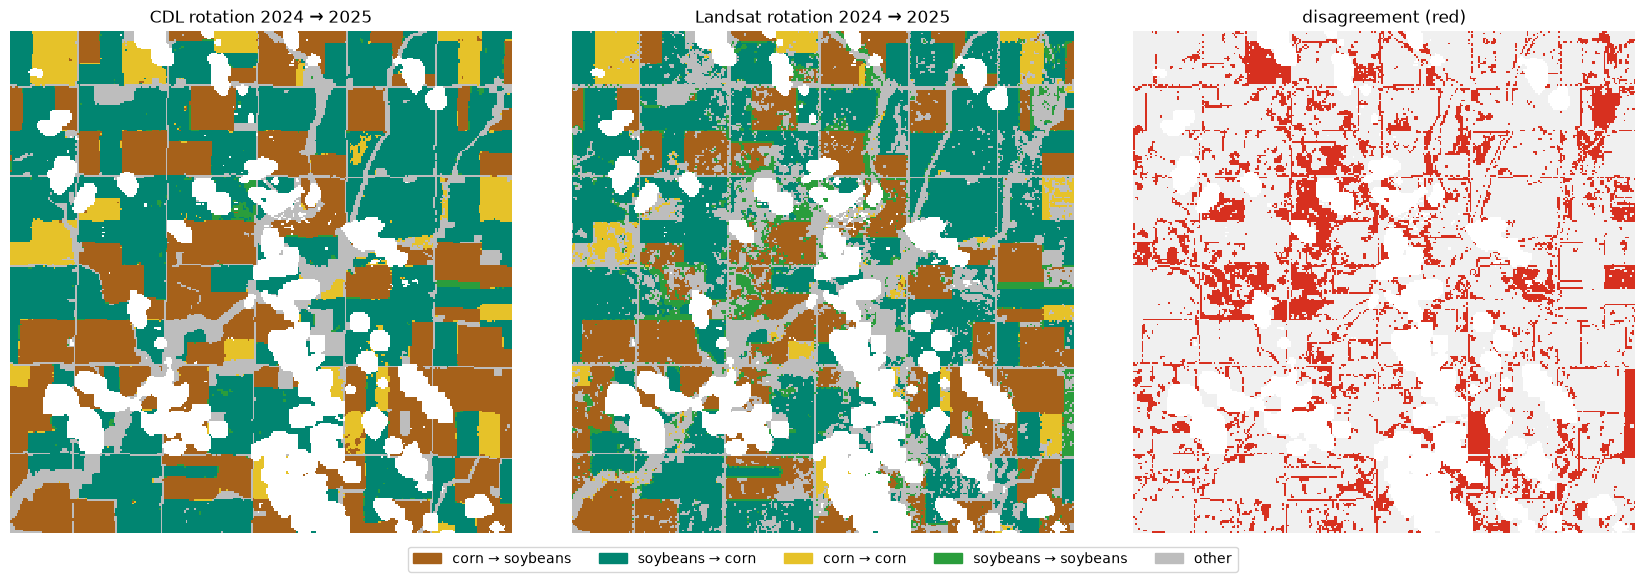

In [14]:
# One possible solution. Rotation classes from a pair of class maps:
ROT = ["corn → soybeans", "soybeans → corn", "corn → corn", "soybeans → soybeans", "other"]
def rotation(m1, m2):  # rotation class of each pixel from two maps
    r = np.full(m1.shape, 4, "int8")  # "other" by default
    r[(m1 == 0) & (m2 == 1)] = 0; r[(m1 == 1) & (m2 == 0)] = 1  # corn to soybeans; soybeans to corn
    r[(m1 == 0) & (m2 == 0)] = 2; r[(m1 == 1) & (m2 == 1)] = 3  # corn on corn; soybeans on soybeans
    return r  # the classes
# from the Landsat maps and from the CDL
rot_l, rot_c = rotation(MAPS[2024], MAPS[2025]), rotation(CDL[2024], CDL[2025])
ev = EVAL  # evaluation pixels
agree = rot_l == rot_c  # pixels where both agree
# agreement share
print(f"rotation class agreement, Landsat vs CDL: {agree[ev].mean():.1%} of the evaluation pixels")
# cross-table of the rotation classes
xt = pd.crosstab(pd.Series([ROT[i] for i in rot_c[ev]], name="CDL"), pd.Series([ROT[i] for i in rot_l[ev]], name="Landsat"),
                 normalize="index").mul(100).round(1)
print("\nrow-normalised (% of each CDL rotation class):"); print(xt.loc[ROT, ROT])  # header and table

# where do they disagree?
size = np.zeros(REF.shape)
# connected corn/soybean fields away from edges
lab, n = ndi.label((CDL[2024] >= 0) & (CDL[2024] <= 1) & ~boundary(CDL[2024]))
size_px = np.bincount(lab.ravel()); size = size_px[lab] * PIX_HA  # field size in hectares at every pixel
cloud24 = ~np.isfinite(LS["2024"].values[0])  # cloud in 2024
# clear pixels within 300 m of a cloud
near_cloud = (ndi.distance_transform_edt(~cloud24) * 30 <= 300) & ~cloud24
groups = {"all evaluation pixels": ev, "field edge": ev & edge, "field interior": ev & ~edge,  # pixel groups
          "interior, fields < 10 ha": ev & ~edge & (size > 0) & (size < 10), "interior, fields ≥ 40 ha": ev & ~edge & (size >= 40),
          "within 300 m of a 2024 cloud": ev & near_cloud, "CDL 2024 = soybeans": ev & (CDL[2024] == 1), "CDL 2024 = corn": ev & (CDL[2024] == 0)}
print("\ndisagreement by location:")  # header
# disagreement per group
print(pd.DataFrame({k: {"pixels": int(m.sum()), "disagreement (%)": (~agree[m]).mean() * 100} for k, m in groups.items()}).T.round(1))

rc = ListedColormap(["#a6611a", "#018571", "#e6c229", "#2a9d3c", "#bdbdbd"])
z = (slice(400, 700), slice(380, 680))  # a 300 x 300 pixel zoom
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))  # three panels
# both rotation maps
for a_, r, t in [(ax[0], rot_c, "CDL rotation 2024 → 2025"), (ax[1], rot_l, "Landsat rotation 2024 → 2025")]:
    # the map zoom
    a_.imshow(np.where(ev, r, np.nan)[z], cmap=rc, vmin=-0.5, vmax=4.5, interpolation="nearest"); a_.set_title(t)
ax[2].imshow(np.where(ev, ~agree, np.nan)[z], cmap=ListedColormap(["#f0f0f0", "#d7301f"]), vmin=-0.5, vmax=1.5, interpolation="nearest")
ax[2].set_title("disagreement (red)")  # title
for a_ in ax:  # every panel
    a_.axis("off")  # no axes
# rotation legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in rc.colors], labels=ROT, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()  # arrange and draw

**Discussion of the solution.**

1. The two rotation maps agree on about **79 %** of the pixels. The swaps (corn → soybeans, soybeans → corn) agree best (77 to 84 %); "corn → corn" and "soybeans → soybeans" agree least (60 to 68 %), and every CDL class loses 13 to 24 % to "other", mostly the Landsat maps calling field pixels grass/pasture or wetland/forest.
2. Disagreement is **twice as high on field edges** (34 %) as inside fields (16 %): mixed 30 m pixels, and edges that differ slightly between the two years in both products. Inside fields, size matters little in this landscape of large fields.
3. It is clearly **higher within 300 m of a 2024 cloud** (28 %): thin cloud, haze and cloud shadow beyond the `QA_PIXEL` mask change the reflectance, and the Random Forest turns that into a wrong class.
4. It is **higher for fields that were corn in 2024** (25 %, against 17 % for soybeans): in mid-July 2024 the Landsat map confused part of the corn with soybeans or grass (its 2024 accuracy is 0.80, against 0.87 for 2025), which also explains the many corn → corn fields that Landsat calls soybeans → corn.
5. Whole-field disagreements in the interior are mostly errors of the Landsat maps (one wrong year makes a wrong rotation). Thin lines along roads, drainage ditches and field boundaries are where **both** products are uncertain, and the CDL is not a better truth there. A few fields are genuinely mixed (a strip of another crop, a replanted part), which neither 30 m map can represent.


## Summary of the experiments


In [15]:
def family(k):  # method family from its name
    if k.split(" | ")[0] in DEEP:  # a deep model
        return "deep (" + k.split(" | ")[1] + ")"  # with its input variant
    if k.startswith("Post"):  # post-classification
        return "post-classification"  # ...
    # classical, with its threshold type
    return "classical, " + ("k·σ threshold" if "σ" in k else "Otsu threshold")
ev_ = evaluation.copy(); ev_["family"] = [family(k) for k in ev_.index]  # the evaluation table with families
# the best method of each family
best = ev_.sort_values("F1", ascending=False).groupby("family", sort=False).head(1)
# header
print("Best method of each family on the 2024 -> 2025 test pair (all evaluation pixels and interior pixels):")
# its scores
print(best[["family", "precision", "recall", "F1", "IoU", "F1, interior pixels"]].round(3).to_string())
# save the tables
evaluation.to_csv(OUT / "change_metrics_2024_2025.csv"); ol.to_csv(OUT / "olofsson_change_area.csv")
# the Landsat transition map
tr_map.rio.write_crs(REF.rio.crs).astype("int32").rio.to_raster(OUT / "transitions_landsat_2024_2025.tif", compress="deflate")
# the best deep change probability, in %
REF.copy(data=(PROB[(best_deep.split(" |")[0], "Sentinel-2 test pair")] * 100).astype("uint8")).rio.to_raster(OUT / "change_probability_s2_2024_2025.tif", compress="deflate")
print("\nwritten:", sorted(p.name for p in OUT.iterdir()))  # files written

Best method of each family on the 2024 -> 2025 test pair (all evaluation pixels and interior pixels):
                                                                                              family  precision  recall     F1    IoU  F1, interior pixels
BIT-style transformer | Sentinel-2 test pair                             deep (Sentinel-2 test pair)      0.965   0.938  0.951  0.907                0.993
Siamese-diff U-Net | Landsat, histogram_match to S2 2023  deep (Landsat, histogram_match to S2 2023)      0.956   0.941  0.949  0.902                0.989
BIT-style transformer | Landsat, cross-calibrated                   deep (Landsat, cross-calibrated)      0.947   0.933  0.940  0.887                0.981
Early-fusion U-Net | Landsat, raw                                                deep (Landsat, raw)      0.972   0.882  0.925  0.860                0.971
Post-classification (Landsat RF maps 2024, 2025)                                 post-classification      0.919   0.909  0.

## Interpretation, caveats and recommended recipe

**What the numbers say** (Landsat / Sentinel-2 mid-July pair 2024 → 2025; CDL change as reference; 79 % of the pixels change, almost all by rotation):

* **Check before you compare.** The Landsat pair is co-registered to 0.1 px; a deliberate 1-pixel shift is caught by `check_coregistration`. Raw surface reflectance is already consistent on invariant targets, and `histogram_match` distorts it when much of the scene really changes.
* **Thresholds must match the share of change.** ±kσ rules assume rare change and fail here (F1 0.10); Otsu works for any share as long as the histogram is bimodal.
* **Unsupervised spectral change confuses crop swaps with season timing.** Classical methods are precise (0.94 to 0.98) but miss 37 to 63 % of the change; multi-band CVA and PCA are better than single indices, and CVA direction separates corn → soybean from soybean → corn, but not from a phenology shift.
* **Supervised methods know what change means.** Post-classification (F1 0.91) gives from-to information but adds the errors of two maps; deep change networks trained on earlier years reach F1 ≈ 0.95 (≈ 0.99 inside fields) and transfer to Landsat after histogram matching to their training domain.
* **The reference matters as much as the method.** Most non-rotation CDL change sits on field edges and is label noise; interior pixels give a much cleaner evaluation.
* **Report areas from a sample, not from the map.** Olofsson's estimator corrects even a map that misses half of the change; better maps give narrower intervals.

**Caveats**

* **CDL is the reference**, for both training and testing; the deep models learn its notion of change (including its edge noise), and scores measure agreement with CDL.
* **Rotation dominates.** With 79 % change and almost all of it rotation, the scores mostly reflect corn vs soybeans; a landscape with rare change (urban growth, deforestation) behaves very differently, and there precision of the change class becomes the hard part.
* **One pair, one date per year.** Mid-July images; with August images the corn/soybean contrast and the scores would be higher.
* **The area sample uses CDL labels**, which are known everywhere here; with real reference data the census check is not available, and the reference labels themselves have errors.
* **Single training runs** (one seed); differences between the deep models (≈ 0.01 F1) are within run-to-run variation.

**Recommended recipe**

1. Put both dates on one grid; run `check_coregistration` and fix any shift above about 0.3 px before anything else.
2. Check radiometry on pseudo-invariant targets; normalise (histogram matching, or a regression on invariant targets) only when it does not remove the change you want to find, and always when crossing sensors.
3. For a quick unsupervised map, use multi-band CVA or PCA of the difference with an Otsu threshold; use CVA direction to label the type of change.
4. When labels exist, prefer supervised change: a Siamese-difference U-Net or a BIT-style model trained on earlier date pairs, or post-classification when from-to classes are needed.
5. Decide what counts as change (here: is rotation change?), and evaluate on a reference that is reliable for that definition (interior pixels, confirmed transitions).
6. Report change **areas** from a stratified sample with `olofsson`, with confidence intervals.

### References
- Daudt, R. C., Le Saux, B., & Boulch, A. (2018). Fully convolutional siamese networks for change detection. *ICIP*, 4063-4067.
- Chen, H., Qi, Z., & Shi, Z. (2021). Remote sensing image change detection with transformers. *IEEE TGRS*, 60, 1-14.
- Malila, W. A. (1980). Change vector analysis: an approach for detecting forest changes with Landsat. *LARS Symposia*, 385.
- Singh, A. (1989). Digital change detection techniques using remotely-sensed data. *International Journal of Remote Sensing*, 10(6), 989-1003.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62-66.
- Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., & Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42-57.
- Boryan, C., Yang, Z., Mueller, R., & Craig, M. (2011). Monitoring US agriculture: the US Department of Agriculture, National Agricultural Statistics Service, Cropland Data Layer program. *Geocarto International*, 26(5), 341-358.
